# Review Dotted Charts

Use the project environment and start Jupyter from the repository root. Run the cells in order, then edit the view settings to inspect the same saved variant in memory.

In [12]:
from base64 import b64encode
from pathlib import Path

from IPython.display import HTML, display

from rendering.renderer import RenderStyle, render_charts
from rendering.views import ViewSpec, load_chart_inputs

root = Path.cwd()
if root.name == "notebooks" and (root.parent / "pyproject.toml").is_file():
    root = root.parent
variants = sorted(
    path.parent for path in (root / "data/processed/injected").glob("*/*/manifest.json")
)
display([str(path.relative_to(root)) for path in variants])

['data/processed/injected/bpic2012/gap_60c363dc8f11e86a',
 'data/processed/injected/bpic2012/gap_c070babcd4466ed2',
 'data/processed/injected/bpic2012/mixed_1ff6322ecf6abe2b']

In [13]:
variant_path = "data/processed/injected/bpic2012/mixed_1ff6322ecf6abe2b"  # Set a Phase-2 directory path or use the first discovered variant.
if variant_path is None and not variants:
    raise FileNotFoundError("Set variant_path to a saved Phase-2 variant directory.")
inputs = load_chart_inputs(root / variant_path if variant_path else variants[0], source_root=root)
role = "both" if inputs.baseline is not None else "modified"
print(inputs.variant_dir)
if role == "modified":
    print("Modified only. Case order and colors use the complete modified log (modified_fallback).")
    print(f"Baseline comparison requires {inputs.baseline_path} and its JSON sidecar.")

for injection in inputs.manifest["injections"]:
    print(
        injection["injection_id"],
        injection["pattern_type"],
        f"{injection['affected']['event_count']} changed events",
    )
    display(injection["target_regions"])

/Users/markuserb/dev/processmining/vlm-for-dotted-charts/data/processed/injected/bpic2012/mixed_1ff6322ecf6abe2b
inj_001 batching 25 changed events


[{'activity_scope': ['A_DECLINED',
   'A_SUBMITTED',
   'W_Afhandelen leads',
   'W_Completeren aanvraag',
   'W_Nabellen incomplete dossiers',
   'W_Nabellen offertes'],
  'case_scope': {'case_ids': ['191290',
    '191683',
    '195157',
    '195737',
    '196909',
    '196960',
    '197470',
    '197527',
    '197572',
    '197825',
    '198182',
    '198424',
    '198681',
    '199363',
    '199417',
    '199426',
    '199480',
    '199498',
    '199540',
    '199570',
    '199597',
    '199663',
    '199666',
    '199717',
    '199729'],
   'type': 'selected'},
  'coordinate_space': 'final_event_log',
  'end_utc': '2012-01-10T10:30:17.619441492+00:00',
  'region_id': 'region_001',
  'start_utc': '2012-01-10T10:29:19.749679727+00:00',
  'time_type': 'interval'}]

inj_002 temporal_gap 85489 changed events


[{'case_scope': {'type': 'all'},
  'coordinate_space': 'final_event_log',
  'end_utc': '2012-01-23T14:39:43+00:00',
  'region_id': 'region_001',
  'start_utc': '2012-01-23T12:39:43+00:00',
  'time_type': 'interval'}]

Use `full` for the shared time range, `time_window` with explicit UTC start and end, or `focused` with an injection or region ID and a positive context such as `12h`. The optional case and activity filters apply to either panel. Candidate overlays show Phase-2 time and case scope on the modified panel. Phase 4 verifies visual labels and boxes.

In [20]:
view = ViewSpec(
    mode="focused",
    start_utc=None,
    end_utc=None,
    injection_id="inj_001",
    region_id=None,
    context="1h",
    case_ids=None,
    activities=None,
)
style = RenderStyle(width_px=2400, height_px=1200, dpi=200, legend=False)
show_candidate_regions = False
charts = render_charts(
    inputs,
    view=view, 
    role="both",      
    style=style, 
    show_candidate_regions=show_candidate_regions
)

UTC window 2012-01-10T09:29:19.749679727+00:00 2012-01-10T11:30:17.619441492+00:00
Baseline • 367 events, 97 case rows, 1560 × 960 px plot, 9.9 px/row
Modified • 390 events, 97 case rows, 1560 × 960 px plot, 9.9 px/row



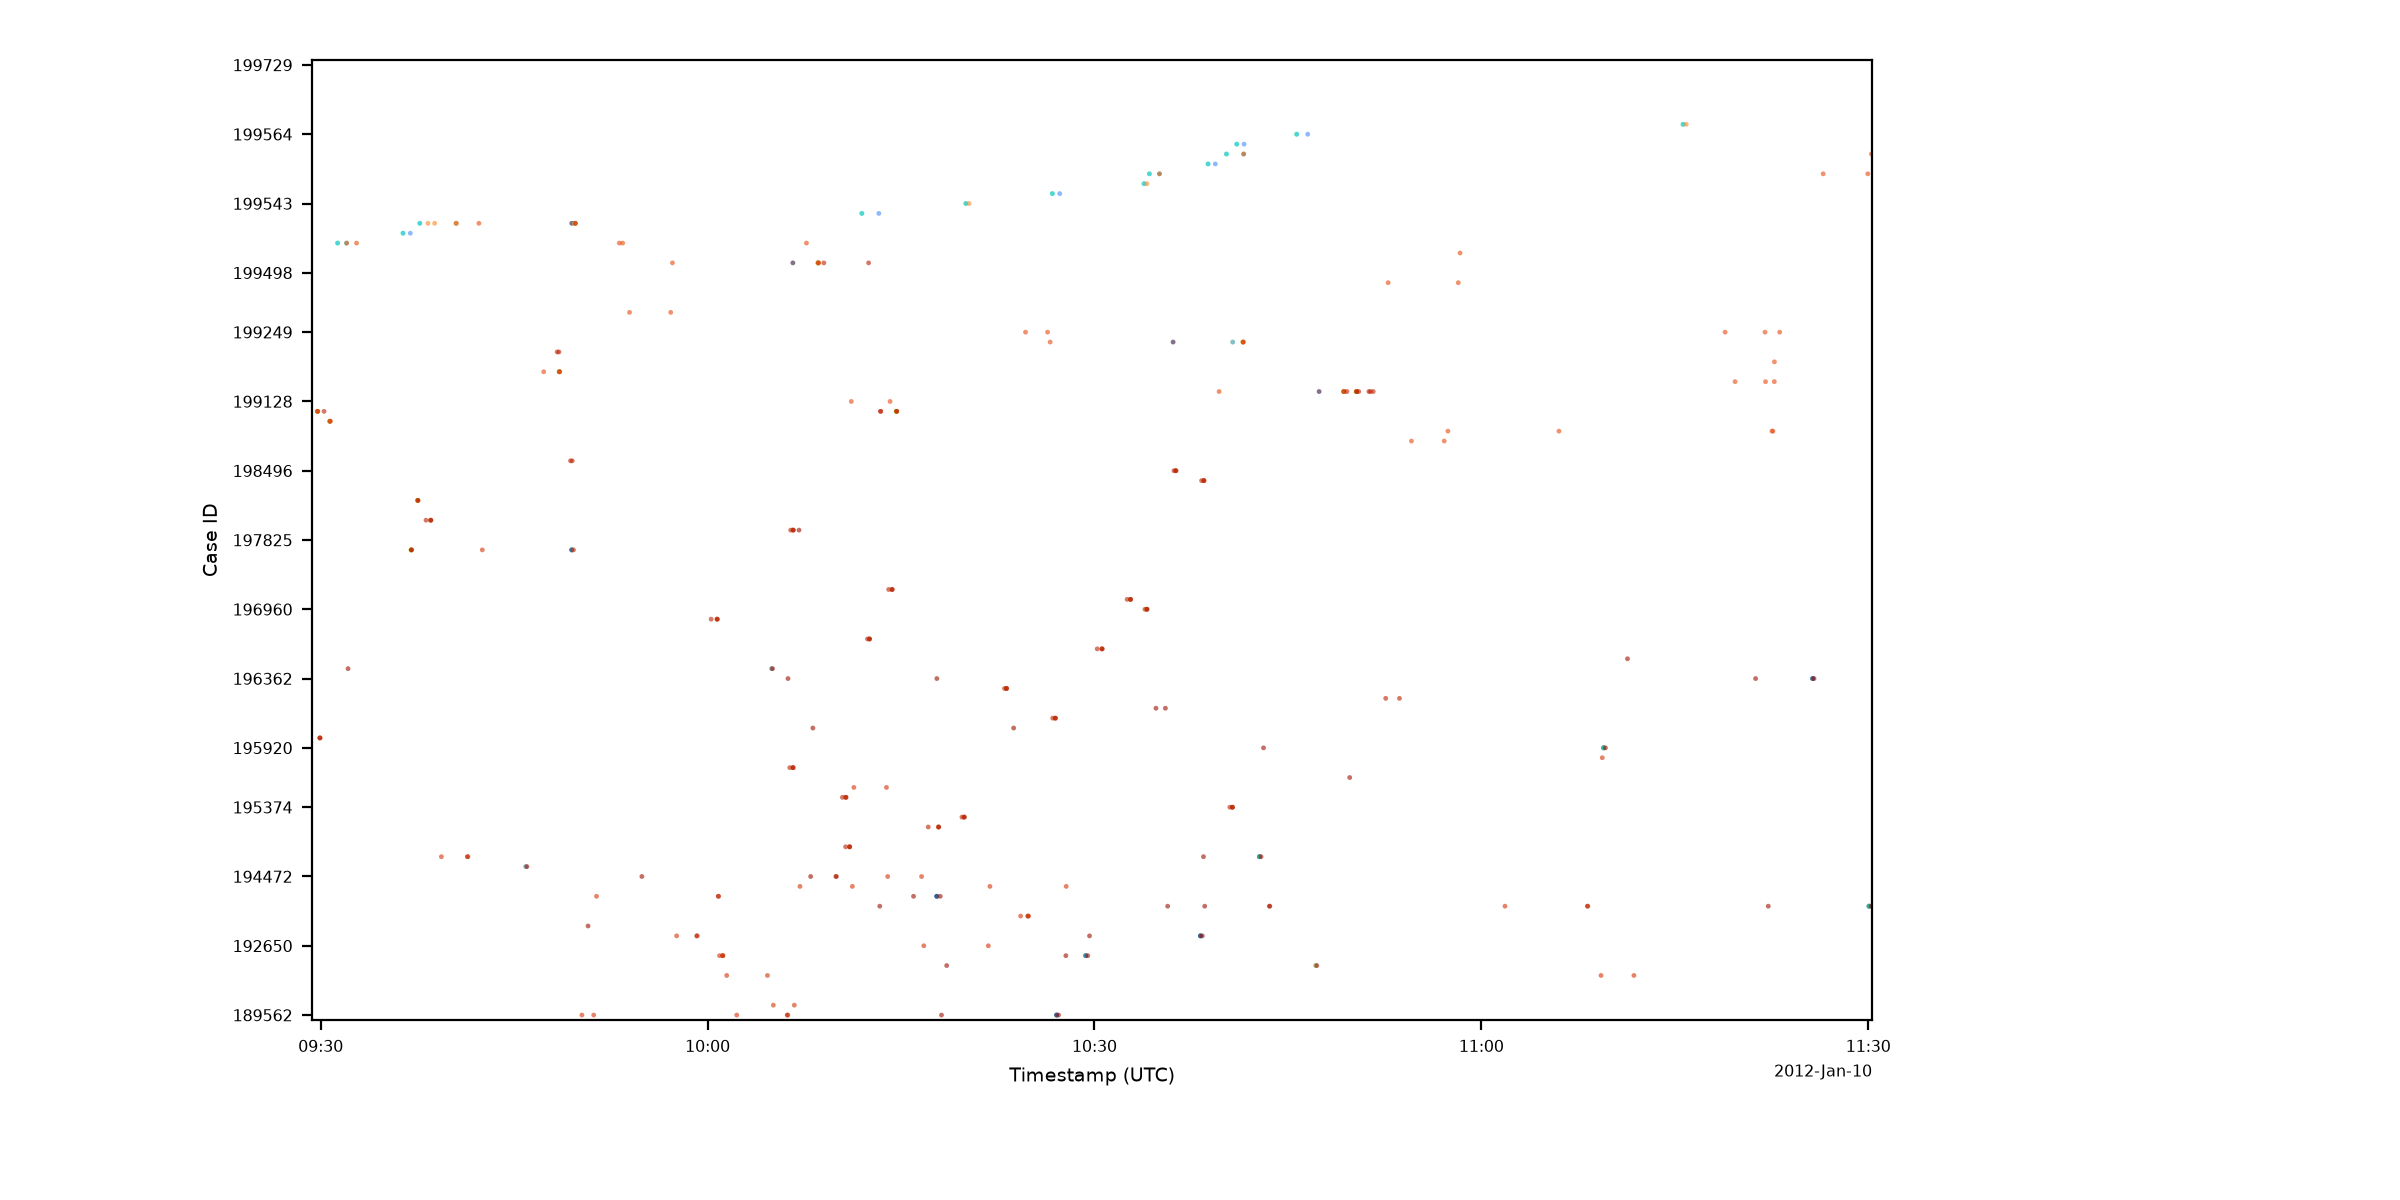
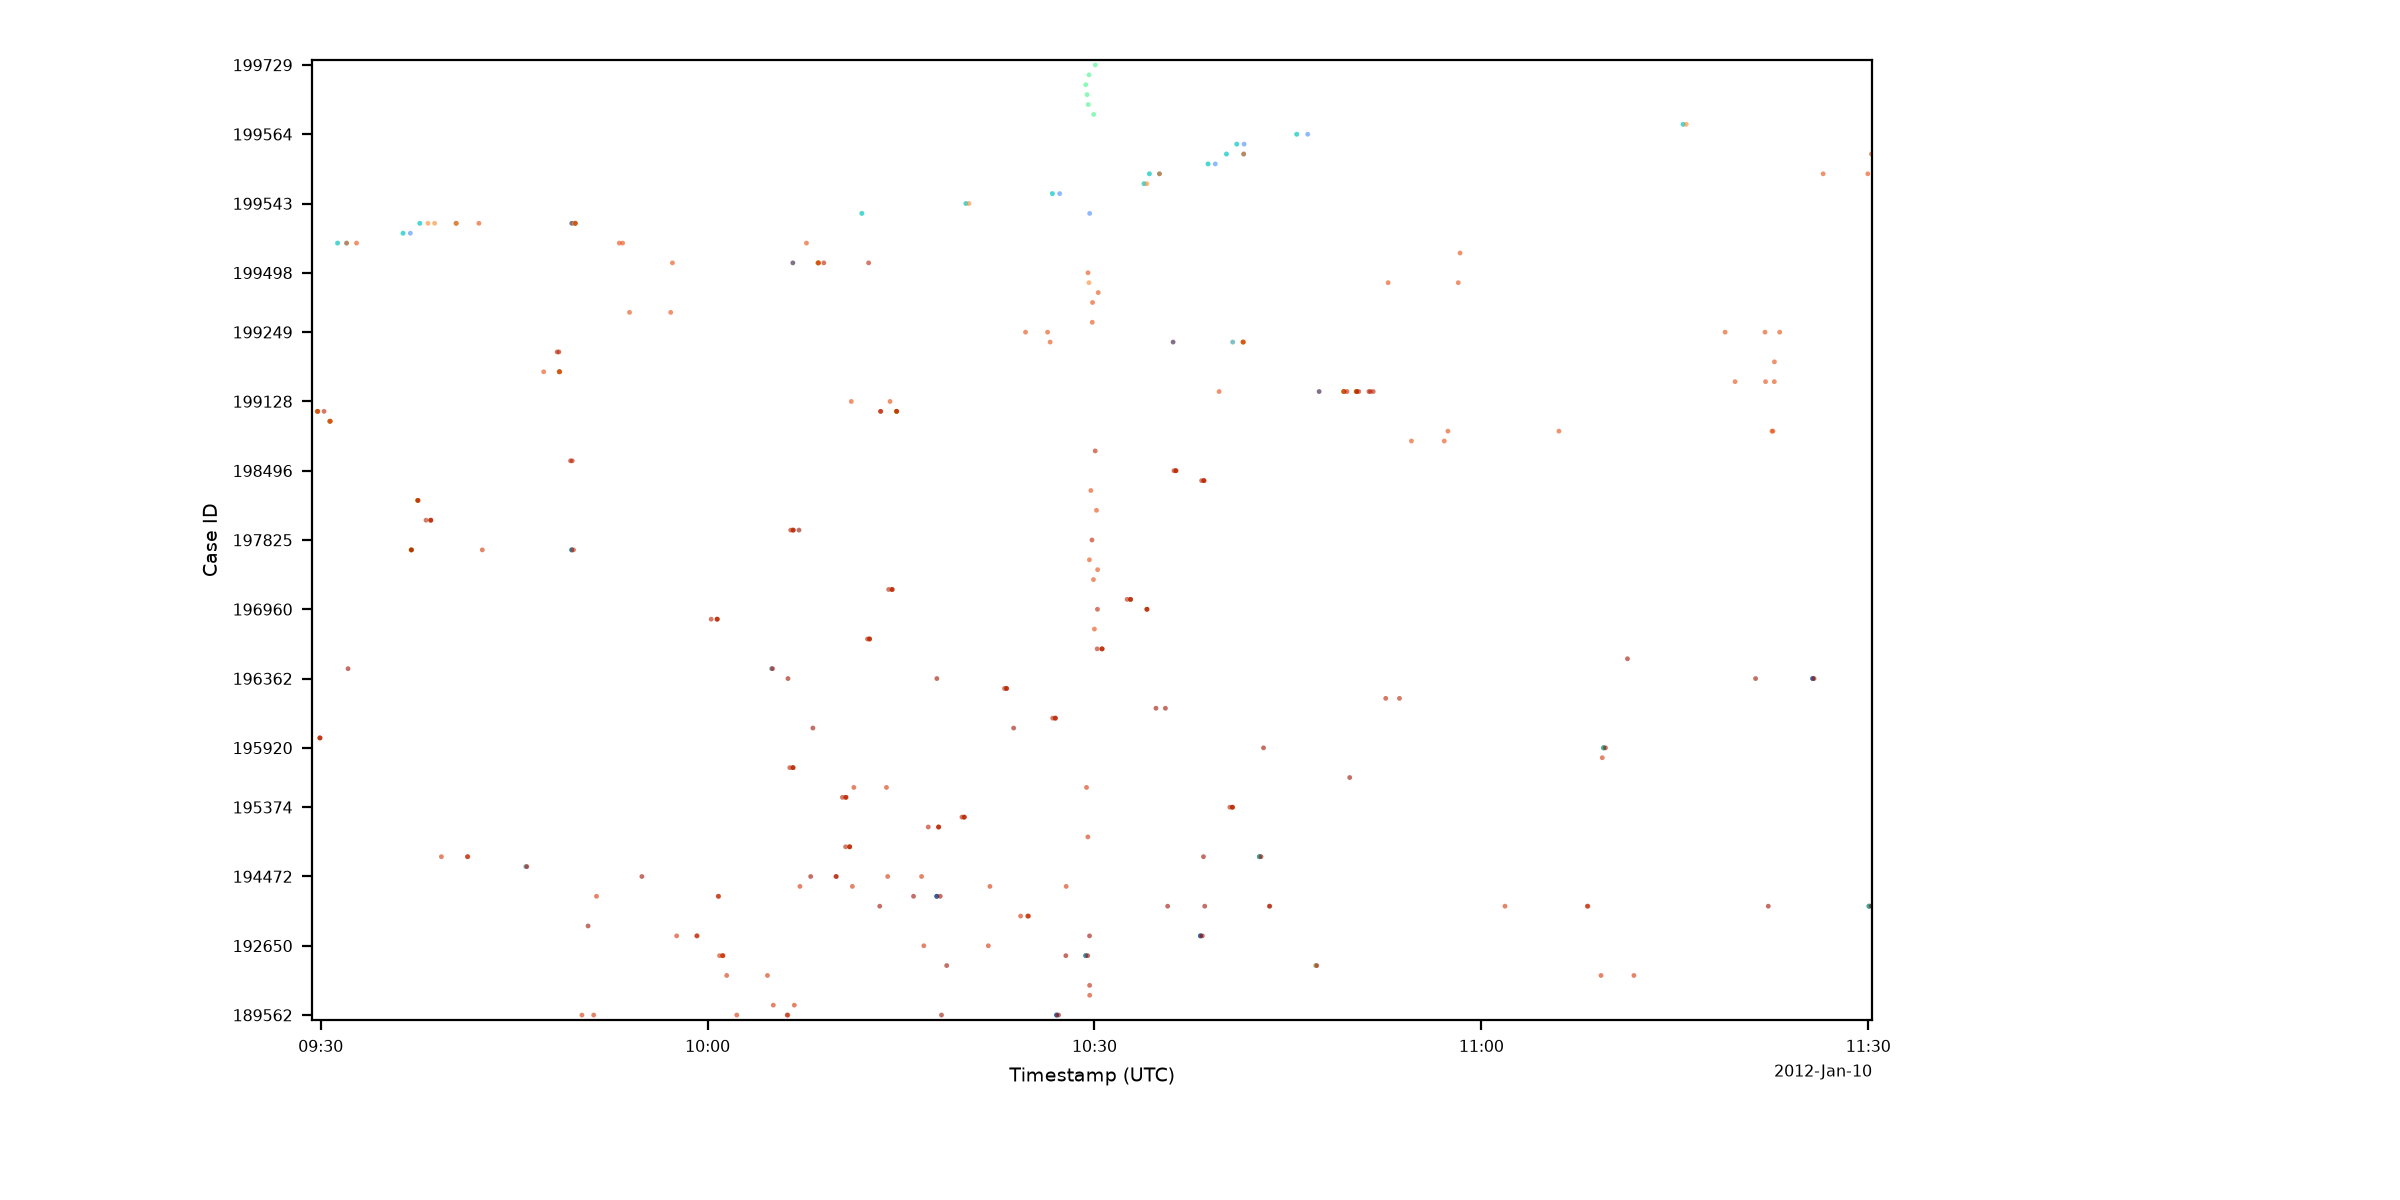

In [21]:
effective = next(iter(charts.values())).view
print("UTC window", *(time.isoformat() for time in effective.time_bounds))
if view.case_ids is not None:
    print(f"Case filter requests {len(view.case_ids)} case rows.")
if view.activities is not None:
    print("Activity filter", ", ".join(view.activities))
if show_candidate_regions:
    print("Candidate regions from Phase 2. Visual verification belongs to Phase 4.")

panels = []
for panel_role, chart in charts.items():
    counts = chart.counts
    density = (
        "" if counts.pixels_per_case_row is None else f", {counts.pixels_per_case_row:.3g} px/row"
    )
    print(
        f"{panel_role.capitalize()} • {counts.events:,} events, {counts.cases:,} case rows, "
        f"{counts.plot_width_px:.0f} × {counts.plot_height_px:.0f} px plot{density}"
    )
    for diagnostic in chart.diagnostics:
        print(f"{panel_role.capitalize()} • {diagnostic}")
    image = b64encode(chart.png_bytes()).decode("ascii")
    panels.append(
        '<figure style="flex:1;min-width:0;margin:0">'
        f"<figcaption>{panel_role.capitalize()}</figcaption>"
        f'<img alt="{panel_role} Dotted Chart" src="data:image/png;base64,{image}" '
        'style="display:block;width:100%;height:auto"></figure>'
    )
display(HTML('<div style="display:flex;gap:12px">' + "".join(panels) + "</div>"))

In [22]:
export_role = "both"  # Set to 'baseline', 'modified', or 'both' to save clean PNGs and metadata.
if export_role is not None:
    from rendering.export import export_charts

    display(
        export_charts(
            inputs,
            view=view,
            role=export_role,
            style=style,
            output_root=root / "data/generated/charts",
        )
    )

{'baseline': PosixPath('/Users/markuserb/dev/processmining/vlm-for-dotted-charts/data/generated/charts/bpic2012/mixed_1ff6322ecf6abe2b/baseline_5e1dd00916d6b21a'),
 'modified': PosixPath('/Users/markuserb/dev/processmining/vlm-for-dotted-charts/data/generated/charts/bpic2012/mixed_1ff6322ecf6abe2b/modified_9d41675b56bf2b7e')}